# ━━━━━━━━━━ SHARED SETUP · belongs to ALL parts (Person 1 owns it) ━━━━━━━━━━

One cell: imports, `SEED`, plot style, loading `learn` / `predict`, `BASE` (base fatal rate) and the two helper functions `plot_cat_vs_target` and `plot_num_vs_target`.

*If the main file already has Person 1's setup, delete this block and keep theirs (the names `learn`, `predict`, `SEED`, `BASE` and the two functions must stay the same).*

In [15]:
# ===== SHARED SETUP (all parts use this) =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 5
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

learn = pd.read_csv("learn.csv")
predict = pd.read_csv("predict.csv")

BASE = learn["fatal"].mean()
print(f"learn {learn.shape} · predict {predict.shape} · base fatal rate {BASE:.1%}")


def plot_cat_vs_target(df, col, min_n=30, top=15, ax=None, title=None):
    """Fatal rate per category (with n on top of each bar). Does not modify df."""
    g = (df.groupby(col, dropna=False)["fatal"].agg(rate="mean", n="size")
           .query("n >= @min_n").sort_values("n", ascending=False).head(top))
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index])
    ax.axhline(BASE, color="crimson", ls="--", lw=1, label=f"base rate {BASE:.1%}")
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by {col} (groups with n >= {min_n})")
    ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
    return g


def plot_num_vs_target(df, col, q=8, ax=None, title=None):
    """Fatal rate per quantile bin of a numeric column. Does not modify df."""
    s = df[col]
    bins = pd.qcut(s, q=q, duplicates="drop")
    g = df.groupby(bins, observed=True)["fatal"].agg(rate="mean", n="size")
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
    ax.axhline(BASE, color="crimson", ls="--", lw=1)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by quantile bins of {col}")
    return g

learn (16979, 42) · predict (4245, 41) · base fatal rate 17.0%


In [16]:
learn.head()

,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,...,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase,fatal
0,A00001,2018,9,USA,Th,19.0,DAYL,VMC,NONE,CLER,T,0,10.0,59,15.0,49,38,7.0,0,30.06,...,091,air,N,FIXD,PERS,NONE,N,PIPER,0,1.0,2.0,1956.0,REC,CARB,NaN,71.0,M,CL3,Landing,0
1,A00002,2011,7,USA,Sa,17.0,DAYL,VMC,NONE,CLER,T,0,5.0,70,21.1,56,0,3.0,0,29.91,...,091,AIR,n,FIXD,INST,NONE,n,AMERICAN AVIATION,0,1.0,2.0,NaN,REC,CARB,108.0,17.0,M,CL1,Maneuvering,1
2,A00004,2013,7,USA,Su,22.0,DAYL,VMC,UNK,FEW,F,0,10.0,80,26.7,73,0,10.0,17,30.06,...,091,AIR,N,FIXD,PERS,UNK,N,LUSCOMBE,0,1.0,2.0,NaN,REC,CARB,84.0,46.0,M,CL3,Landing,0
3,A00005,2019,9,USA,Fr,0.0,DAYL,VMC,BKN,NaN,T,10208,10.0,80,26.7,33,261,6.0,0,30.07,...,091,air,n,FIXD,PERS,NONE,N,AMERICAN AVIATION,1,1.0,4.0,1976.0,REC,CARB,150.0,31.0,M,CL1,Enroute,1
4,A00006,2008,4,USA,Su,1.0,DAYL,VMC,NONE,CLER,F,0,10.0,62,16.7,36,261,13.0,18,29.90,...,091,AIR,N,FIXD,PERS,NONE,n,CESSNA,0,1.0,4.0,NaN,REC,CARB,174.0,68.0,M,CL3,Approach,0


In [17]:
predict.head()

,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,...,apt_elev,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase
0,A00003,2015,6,USA,Mo,16.0,DAYL,VMC,NaN,NaN,T,0,10.0,75,23.9,37,183,4.0,0,29.97,...,76.0,091,AIR,N,RETR,PERS,NONE,n,SHORT BROTHERS PLC,1,1.0,2.0,1987.0,TP,NaN,0.0,59.0,M,CL2,Maneuvering
1,A00009,2020,8,USA,Fr,19.0,DAYL,VMC,BKN,NaN,F,3832,10.0,75,23.9,64,70,7.0,0,29.95,...,NaN,137,AIR,N,FIXD,AAPL,NONE,N,AIR TRACTOR,0,1.0,1.0,2018.0,TP,NaN,NaN,55.0,M,CL2,Maneuvering
2,A00023,2019,2,USA,We,2.0,NDRK,VMC,NONE,CLER,F,0,10.0,0,-17.8,0,34,12.0,0,0.00,...,NaN,091,AIR,n,FIXD,PERS,NONE,N,CESSNA,0,1.0,4.0,1974.0,REC,CARB,NaN,31.0,M,CL1,Enroute
3,A00025,2021,9,USA,Tu,19.0,DAYL,VMC,NaN,SCAT,T,0,NaN,87,30.6,72,201,3.0,0,30.05,...,NaN,091,AIR,N,RETR,PERS,NONE,Y,PIPER,1,2.0,4.0,2001.0,REC,CARB,185.0,24.0,M,CL1,Enroute
4,A00034,2016,8,USA,Mo,7.0,NITE,VMC,NONE,CLER,T,0,10.0,90,32.2,74,194,7.0,0,29.80,...,418.0,091,AIR,N,RETR,PERS,NONE,n,BEECH,1,1.0,5.0,1983.0,REC,FINJ,272.0,60.0,F,CL2,Initial climb


Predict has one less column than learn, which is "fatal", because that is the column we are trying to predict.

In [18]:
learn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16979 entries, 0 to 16978
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   row_id               16979 non-null  object 
 1   ev_year              16979 non-null  int64  
 2   ev_month             16979 non-null  int64  
 3   ev_country           16979 non-null  object 
 4   ev_dow               16979 non-null  object 
 5   ev_hour              16960 non-null  float64
 6   light_cond           16953 non-null  object 
 7   wx_cond_basic        16960 non-null  object 
 8   sky_cond_ceil        14977 non-null  object 
 9   sky_cond_nonceil     14158 non-null  object 
 10  gust_ind             16979 non-null  object 
 11  sky_ceil_ht          16979 non-null  int64  
 12  vis_sm               16258 non-null  float64
 13  wx_temp              16979 non-null  int64  
 14  wx_temp_c            16979 non-null  float64
 15  wx_dew_pt            16979 non-null 

In [19]:
display(learn.duplicated().value_counts())
predict.duplicated().value_counts()

False    16979
Name: count, dtype: int64

False    4245
Name: count, dtype: int64

There are no duplicated rows in any of the datasets.

# Missing Values:

In [30]:
learn.isna().sum()

row_id                    0
ev_year                   0
ev_month                  0
ev_country                0
ev_dow                    0
ev_hour                  19
light_cond               26
wx_cond_basic            19
sky_cond_ceil          2002
sky_cond_nonceil       2821
gust_ind                  0
sky_ceil_ht               0
vis_sm                  721
wx_temp                   0
wx_temp_c                 0
wx_dew_pt                 0
wind_dir_deg              0
wind_vel_kts           3603
gust_kts                  0
altimeter                 0
apt_dist                  0
apt_elev               5712
far_part                  1
acft_category             0
homebuilt                 0
fixed_retractable         0
type_fly                787
flt_plan_filed          242
second_pilot           1184
acft_make                 1
ifr_equipped_cert         0
num_eng                 485
total_seats            1206
acft_year              6816
eng_type                602
carb_fuel_injection 

In [32]:
learn.nunique()

row_id                 16979
ev_year                   16
ev_month                  12
ev_country                 1
ev_dow                     7
ev_hour                   24
light_cond                 7
wx_cond_basic              3
sky_cond_ceil              5
sky_cond_nonceil           5
gust_ind                   2
sky_ceil_ht             3497
vis_sm                    43
wx_temp                  161
wx_temp_c                161
wx_dew_pt                139
wind_dir_deg             361
wind_vel_kts              49
gust_kts                  55
altimeter                270
apt_dist                 142
apt_elev                3579
far_part                  15
acft_category             19
homebuilt                  4
fixed_retractable          2
type_fly                  22
flt_plan_filed             7
second_pilot               4
acft_make               2914
ifr_equipped_cert          2
num_eng                    7
total_seats              135
acft_year                102
eng_type      

In [36]:
learn[["wx_temp", "wx_temp_c"]]

,wx_temp,wx_temp_c
0,59,15.0
1,70,21.1
2,80,26.7
3,80,26.7
4,62,16.7
...,...,...
16974,67,19.4
16975,36,2.2
16976,17,-8.3
16977,57,13.9


As we can see, ev_country only has one unique value, which is USA, so this column can be dropped

# ━━━━━━━━━━ PART 4 · Aircraft and engine (Person 4) ━━━━━━━━━━

Columns covered (11): `acft_category`, `homebuilt`, `fixed_retractable`, `acft_make`, `ifr_equipped_cert`, `num_eng`, `total_seats`, `acft_year`, `eng_type`, `carb_fuel_injection`, `eng_power`.

NB0 does not change the data and does not train models. When a cleaning step is needed just to *look* at something (for example upper-casing a category), it is done on a throw-away copy, and the real cleaning is listed as a decision for NB1 at the end of this part.

In [20]:
# Only needed by Part 4
import re

GROUP = ["acft_category", "homebuilt", "fixed_retractable", "acft_make", "ifr_equipped_cert",
         "num_eng", "total_seats", "acft_year", "eng_type", "carb_fuel_injection", "eng_power"]

## Part 4 · 1. Overview of the group

**What we do:** data types, missing values and cardinality of the 11 columns, in `learn` and in `predict`.

In [21]:
ov = pd.DataFrame({
    "dtype": learn[GROUP].dtypes.astype(str),
    "missing_learn_%": (learn[GROUP].isna().mean() * 100).round(1),
    "missing_predict_%": (predict[GROUP].isna().mean() * 100).round(1),
    "n_unique": learn[GROUP].nunique(),
})
ov

,dtype,missing_learn_%,missing_predict_%,n_unique
acft_category,object,0.0,0.0,19
homebuilt,object,0.0,0.0,4
fixed_retractable,object,0.0,0.0,2
acft_make,object,0.0,0.0,2914
ifr_equipped_cert,int64,0.0,0.0,2
num_eng,float64,2.9,2.8,7
total_seats,float64,7.1,7.2,135
acft_year,float64,40.1,39.8,102
eng_type,object,3.5,3.7,11
carb_fuel_injection,object,21.2,21.5,2


**Interpretation.**
- Missingness is very uneven: `acft_year` (40%), `carb_fuel_injection` (21%), `eng_power` (11%), `total_seats` (7%), `eng_type` (3.5%), `num_eng` (2.9%). The other six columns are complete. `learn` and `predict` have similar missing rates, which is good (no shift in how the data was collected).
- `acft_make` has 2,914 distinct values: it is a free-text field, not a real category (section 3).
- `num_eng`, `total_seats`, `acft_year` and `eng_power` are floats only because of the NaNs.

**→ NB1:** missing values need an explicit strategy per column (imputation and/or a missing indicator). Section 6 shows that the 40% in `acft_year` is not random.

## Part 4 · 2. Inconsistent case: `acft_category` and `homebuilt`

**What we do:** the brief warns that `AIR`/`air`, `HELI`/`heli` and `Y`/`y` coexist. We check how widespread it is (also in `predict`) and whether the lowercase rows mean something different. We work on a copy `A`; `learn` is untouched.

In [22]:
for col in ["acft_category", "homebuilt"]:
    print(pd.concat({"learn": learn[col].value_counts(), "predict": predict[col].value_counts()}, axis=1)
            .fillna(0).astype(int).sort_values("learn", ascending=False), "\n")

print("rows with lowercase acft_category:", (learn.acft_category.str.islower()).sum(),
      f"({learn.acft_category.str.islower().mean():.1%})")
print("rows with lowercase homebuilt:    ", (learn.homebuilt.str.islower()).sum(),
      f"({learn.homebuilt.str.islower().mean():.1%})")

               learn  predict
acft_category                
AIR            10899     2746
air             3655      885
HELI            1285      325
heli             382       85
GLI              208       61
BALL             105       21
WSFT              98       25
GYRO              90       18
gli               64       30
PPAR              53       13
wsft              40       10
ball              31        9
gyro              29       10
ppar              19        3
ULTR              13        2
ultr               4        0
PLFT               2        1
RCKT               1        0
BLIM               1        0
plft               0        1 

           learn  predict
homebuilt                
N          10894     2760
n           3707      912
Y           1797      426
y            581      147 

rows with lowercase acft_category: 4224 (24.9%)
rows with lowercase homebuilt:     4288 (25.3%)


Fatal rate: uppercase vs lowercase spelling (same category?)
            mean   size
was_lower              
False      0.171  12755
True       0.168   4224 



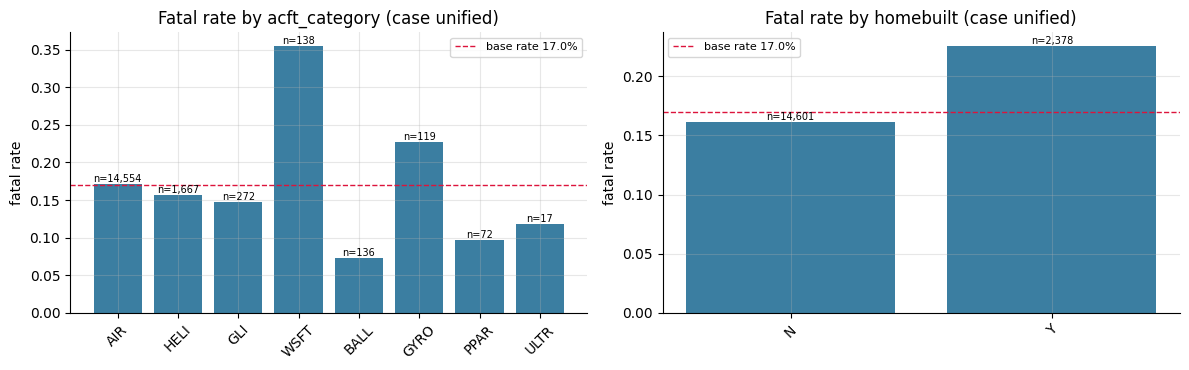

In [23]:
A = learn.copy()                                  # throw-away copy for analysis only
A["acft_category_u"] = A["acft_category"].str.upper()
A["homebuilt_u"] = A["homebuilt"].str.upper()
A["was_lower"] = A["acft_category"].str.islower()

print("Fatal rate: uppercase vs lowercase spelling (same category?)")
print(A.groupby("was_lower")["fatal"].agg(["mean", "size"]).round(3), "\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_cat_vs_target(A, "acft_category_u", min_n=15, ax=ax[0], title="Fatal rate by acft_category (case unified)")
plot_cat_vs_target(A, "homebuilt_u", min_n=15, ax=ax[1], title="Fatal rate by homebuilt (case unified)")
plt.tight_layout(); plt.show()

**Interpretation.**
- About a quarter of the rows are lowercase (`air` 3,655 vs `AIR` 10,899, `n` 3,707 vs `N` 10,894...) and `predict` has the same pattern, so a model fed the raw strings would treat `AIR` and `air` as different levels.
- Lowercase is **noise in the spelling**, not information: the fatal rate is about the same in both groups. After unifying, the categories behave sensibly: airplanes and helicopters are close to the base rate (17%/16%), weight-shift (`WSFT`) is much riskier (36%), balloons and powered parachutes are safer (7–10%). Homebuilt aircraft are more fatal (23% vs 16%).
- Several categories are tiny (`PLFT` 2, `RCKT` 1, `BLIM` 1, `ULTR` 17): their rates are meaningless.

**→ NB1:** upper-case both columns (and apply the same function to `predict`); group categories with fewer than about 30 rows into `OTHER`.

## Part 4 · 3. Aircraft make: `acft_make`

**What we do:** study the cardinality, the spelling variants and the rare makes. Normalisation here (upper case, remove punctuation and company suffixes) is only used to *measure* how much of the 2,914 distinct values are really the same make.

In [24]:
def norm_make(s):
    s = str(s).upper()
    s = re.sub(r"[^A-Z0-9 ]", "", s)
    s = re.sub(r"\b(INC|CORP|CORPORATION|CO|COMPANY|LLC|LTD|THE)\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

A["make_n"] = A["acft_make"].map(norm_make)
P = predict.copy(); P["make_n"] = P["acft_make"].map(norm_make)

vc = A["make_n"].value_counts()
print(f"distinct raw values: {learn.acft_make.nunique():,} · after light normalisation: {A.make_n.nunique():,}")
print(f"makes with >=100 rows: {(vc >= 100).sum()} · >=30 rows: {(vc >= 30).sum()} · <=5 rows: {(vc <= 5).sum():,} · exactly 1 row: {(vc == 1).sum():,}")
print(f"share of rows covered by top 10 / 50 / 200 makes: "
      f"{vc.head(10).sum()/len(A):.0%} / {vc.head(50).sum()/len(A):.0%} / {vc.head(200).sum()/len(A):.0%}")
print(f"share of rows that belong to makes with <=5 rows: {vc[vc <= 5].sum()/len(A):.1%}")
print(f"share of predict rows whose (normalised) make never appears in learn: {(~P.make_n.isin(A.make_n)).mean():.1%}")
print("\nSpelling variants, e.g. ROBINSON and CESSNA:")
print(learn[learn.acft_make.str.upper().str.contains("ROBINSON HELI|^ROBINSON$")].acft_make.value_counts().head(6).to_string())
print(learn[learn.acft_make.str.upper().str.contains("CESSNA")].acft_make.value_counts().head(5).to_string())

distinct raw values: 2,914 · after light normalisation: 2,803
makes with >=100 rows: 17 · >=30 rows: 50 · <=5 rows: 2,614 · exactly 1 row: 2,299
share of rows covered by top 10 / 50 / 200 makes: 56% / 71% / 82%
share of rows that belong to makes with <=5 rows: 18.6%
share of predict rows whose (normalised) make never appears in learn: 13.2%

Spelling variants, e.g. ROBINSON and CESSNA:


ValueError: Cannot mask with non-boolean array containing NA / NaN values

In [ ]:
top = vc[vc >= 100].index
g = (A[A.make_n.isin(top)].groupby("make_n")["fatal"].agg(rate="mean", n="size").sort_values("rate"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(g.index, g["rate"], color="#3b7ea1"); ax[0].axvline(BASE, color="crimson", ls="--")
for i, (r, n) in enumerate(zip(g["rate"], g["n"])): ax[0].text(r, i, f" n={n}", va="center", fontsize=7)
ax[0].set_title("Fatal rate for the 17 makes with >=100 rows"); ax[0].set_xlabel("fatal rate")

rank = np.arange(1, len(vc) + 1)
ax[1].plot(rank, vc.values.cumsum() / vc.sum()); ax[1].set_xscale("log")
ax[1].set_title("Cumulative share of rows covered by the top-k makes"); ax[1].set_xlabel("k (log)")
plt.tight_layout(); plt.show()

rare = A["make_n"].map(vc) <= 5
print("fatal rate, makes with <=5 rows vs the rest:", round(A[rare].fatal.mean(), 3), "vs", round(A[~rare].fatal.mean(), 3))

**Interpretation.**
- Light normalisation only reduces 2,914 values to ~2,800 and merges the big duplicates (`ROBINSON` vs `ROBINSON HELICOPTER`, `CESSNA` vs `CESSNA AIRCRAFT CO`). The remaining ones are mostly one-off names (homebuilders, individuals, old manufacturers): ~2,300 makes appear only once.
- It is a long-tail variable: only 17 makes have ≥ 100 rows (top 10 ≈ 56% of the rows, top 50 ≈ 71%) while ~19% of the rows belong to makes with ≤ 5 rows.
- About **13% of `predict` rows have a make that never appears in `learn`**, so the model will have to deal with unseen categories. A plain one-hot over all makes would be huge and mostly useless.
- There *is* signal in the big makes: Boeing 3%, Schweizer 7%, Maule 8% versus Cirrus 33%, Vans 29%, Mooney 29%, Beech 27% (base rate 17%). Rare makes are riskier than average (21% vs 16%), probably because they are homebuilt/experimental or old aircraft.

**→ NB1:** (1) normalise the text; (2) keep the top ~30–50 makes and group the rest as `OTHER` (or use frequency encoding / target encoding **inside** the cross-validation to avoid leakage); (3) add a `make_is_rare` flag; (4) make sure the encoding handles makes unseen in `learn`.

## Part 4 · 4. Other categorical columns versus the target

**What we do:** `fixed_retractable`, `ifr_equipped_cert`, `num_eng`, `eng_type` and `carb_fuel_injection` against `fatal`. Missing values are kept as their own group (`dropna=False`) so we can see if missing is informative.

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
plot_cat_vs_target(A, "fixed_retractable", min_n=1, ax=ax[0, 0])
plot_cat_vs_target(A, "ifr_equipped_cert", min_n=1, ax=ax[0, 1])
plot_cat_vs_target(A, "num_eng", min_n=1, ax=ax[0, 2])
plot_cat_vs_target(A, "eng_type", min_n=1, ax=ax[1, 0])
plot_cat_vs_target(A, "carb_fuel_injection", min_n=1, ax=ax[1, 1])
ax[1, 2].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
print("eng_type vs carb_fuel_injection (counts):")
print(pd.crosstab(A.eng_type.fillna("NaN"), A.carb_fuel_injection.fillna("NaN")))
print("\nnum_eng == 0 by aircraft category:")
print(A[A.num_eng == 0].acft_category_u.value_counts())

**Interpretation.**
- **Retractable gear** is clearly riskier (24% vs 15%). Faster, more complex aircraft: a strong, simple feature.
- `num_eng`: twins (2) are riskier (22%) than singles (16.5%). `num_eng = 0` (243 rows, 7% fatal) are gliders and balloons, so it is a valid value, not an error. 3, 4, 6, 8 engines are almost never seen (≤ 17 rows).
- `eng_type`: `REC` (piston) is 83% of the data. `TP` turboprop has the highest rate (23%); `TF` turbofan is the lowest (9%, large airliners). Rare codes (`HR`, `GTFN`, `LR`, `ELEC`, `NONE`, `UNK`) have ≤ 23 rows.
- `carb_fuel_injection`: fuel-injected is riskier (22% vs 15%). But `NaN` is **structural**: it only makes sense for piston engines, and it is missing for 73–84% of turbine engines and 100% of electric/no-engine. That is "not applicable", not "unknown". Within `REC` it is missing for only 9%.
- `ifr_equipped_cert` has a weak effect (19% vs 17%).

**→ NB1:** keep `NaN` in `carb_fuel_injection` as an explicit category (`NOT_APPLICABLE`/`UNKNOWN`), group rare `eng_type` codes, cap `num_eng` at 3+ (or treat as category). Question: `retractable`, `eng_type` and `num_eng` are probably correlated (powerful complex aircraft): check redundancy during feature selection.

## Part 4 · 5. The column whose unit changes: `eng_power`

**What we do:** the dictionary says `eng_power` is horsepower for piston and turboprop engines and pounds of thrust for jets. We plot it split by `eng_type` and look at zeros and extremes.

In [ ]:
order = ["ELEC", "REC", "TP", "TS", "TJ", "TF"]
print(A.groupby("eng_type")["eng_power"].describe().round(0).loc[lambda d: d["count"] > 0])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
data = [A.loc[(A.eng_type == t) & (A.eng_power > 0), "eng_power"] for t in order]
ax[0].boxplot(data, tick_labels=[f"{t}\n(n={len(d)})" for t, d in zip(order, data)], showfliers=True)
ax[0].set_yscale("log"); ax[0].set_title("eng_power by eng_type (log scale, zeros excluded)"); ax[0].set_ylabel("HP or lbs of thrust")
ax[1].hist(np.log10(A.loc[A.eng_power > 0, "eng_power"]), bins=60, color="#3b7ea1")
ax[1].set_title("log10(eng_power): mixture of units"); ax[1].set_xlabel("log10(eng_power)")
plt.tight_layout(); plt.show()

print("\neng_power == 0:", (A.eng_power == 0).sum(), "rows · by eng_type:")
print(A[A.eng_power == 0].eng_type.value_counts(dropna=False).head())
print("\nlowest power among jets (lbs of thrust should be in the thousands):")
print(A[A.eng_type.isin(["TF", "TJ"]) & (A.eng_power > 0)].eng_power.nsmallest(5).tolist())
print("piston (REC) engines above 1,500 HP:", ((A.eng_type == "REC") & (A.eng_power > 1500)).sum(), "→ mostly large vintage aircraft")
print("\nmissing eng_power by eng_type (share):")
print(A.eng_power.isna().groupby(A.eng_type.fillna("NaN")).mean().round(2).loc[lambda s: s > 0])

In [ ]:
# Does power matter inside each unit family? (fatal rate by quantile bin, piston only)
rec = A[(A.eng_type == "REC") & (A.eng_power > 0)]
plot_num_vs_target(rec, "eng_power", q=8, title="Piston engines only: fatal rate by eng_power bin (HP)")
plt.tight_layout(); plt.show()
print("Fatal rate by eng_type, power==0 vs >0 (piston):",
      A[A.eng_type == "REC"].groupby(A.eng_power.eq(0))["fatal"].mean().round(3).to_dict())

**Interpretation.**
- The unit problem is real and big: piston engines are around 100–300 (HP), turboprops ~750 HP, but turbofans have a median of ~8,900 and go up to 264,190 (lbs of thrust, with outliers that look like errors). The histogram in log scale is a mix of two populations. A single numeric `eng_power` makes a jet look 50× "more powerful" than a piston when it has nothing to do with it, and it would dominate any distance- or scale-based model (and the mean/std).
- `eng_power = 0` in 171 rows (147 of them piston): impossible, it is a missing-value code. A few jets have power < 1,000 (probably HP-style entries in the wrong unit).
- `eng_power` is missing together with `eng_type`: for rows where `eng_type` is `NaN` it is missing 95% of the time.
- Within piston engines, check the last plot: if the fatal rate changes across HP bins there is signal once the unit is homogeneous (this is the comparison that makes sense; mixing HP and lbs is not).

**→ NB1:** treat `eng_power = 0` as `NaN`; build `eng_power_hp` (piston/turboprop/turboshaft/electric) and `eng_thrust_lbs` (TF/TJ) as two separate features (or a log-transform *interacted* with engine family). Cap or winsorise extreme values. Question: impute power by median per `eng_type`, or only flag it?

## Part 4 · 6. Impossible values: `total_seats` and `acft_year`

**What we do:** look for values that cannot be true (`acft_year` after the accident year or absurdly old, odd seat counts) and understand why `acft_year` is missing 40% of the time.

In [ ]:
print("=== total_seats ===")
print("seats == 0:", (A.total_seats == 0).sum(), " seats > 100:", (A.total_seats > 100).sum(), " max:", A.total_seats.max())
print(A.total_seats.describe().round(1).to_dict())
print("\nseats > 100: category / operation / fatal rate")
big = A[A.total_seats > 100]
print(big.acft_category_u.value_counts().to_dict(), big.far_part.value_counts().head(3).to_dict(), "fatal:", round(big.fatal.mean(), 3))
print("odd seat counts (3,5,7,9) vs even (2,4,6,8):", A.total_seats.isin([3, 5, 7, 9]).sum(), "vs", A.total_seats.isin([2, 4, 6, 8]).sum())
print("seats, median by category:", A.groupby("acft_category_u").total_seats.median().to_dict())

print("\n=== acft_year ===")
y = A["acft_year"]
print("acft_year == 0:", (y == 0).sum(), "· < 1900 (and > 0):", ((y > 0) & (y < 1900)).sum(), "· > ev_year:", (y > A.ev_year).sum(),
      "· max:", y.max(), "(accident years go up to", A.ev_year.max(), ")")
print("how far in the future (years):", (y - A.ev_year)[y > A.ev_year].value_counts().to_dict())
print("aircraft age at accident, valid rows:", (A.ev_year - y)[(y > 1900) & (y <= A.ev_year)].describe().round(1).to_dict())

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(A.total_seats.clip(upper=20).dropna(), bins=np.arange(-0.5, 21.5, 1), color="#3b7ea1")
ax[0].set_title("total_seats (clipped at 20)"); ax[0].set_xlabel("seats")
ax[1].hist(y[(y > 1900)].dropna(), bins=50, color="#3b7ea1"); ax[1].set_title("acft_year (valid values)")
miss = A.groupby("ev_year")["acft_year"].apply(lambda s: s.isna().mean())
ax[2].bar(miss.index, miss.values * 100, color="#c0504d"); ax[2].set_title("% missing acft_year by ACCIDENT year"); ax[2].set_ylabel("% missing")
plt.tight_layout(); plt.show()
print((miss * 100).round(0).astype(int).to_dict())

In [ ]:
# Is missing acft_year informative?  Compare only the years where it is almost always present.
late = A[A.ev_year >= 2014]
print("ev_year >= 2014: share missing =", round(late.acft_year.isna().mean(), 3))
print("fatal rate, acft_year missing vs present (all years):", A.groupby(A.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate, acft_year missing vs present (2014+):    ", late.groupby(late.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate by aircraft-year band:")
print(A.groupby(pd.cut(A.acft_year, [1900, 1950, 1970, 1990, 2005, 2026]), observed=True)["fatal"].agg(["mean", "size"]).round(3))
print("\nfatal rate by seats band:")
print(A.groupby(pd.cut(A.total_seats, [-1, 1, 2, 4, 6, 10, 100, 1e5]), observed=True)["fatal"].agg(["mean", "size"]).round(3))

**Interpretation.**
- **`total_seats`:** 37 rows with 0 seats (gliders and balloons mostly, so partly legitimate: pilot not counted) and **168 rows with > 100 seats, up to 8,300**. These are all airplanes, 158 of them `far_part 121` (airlines): large aircraft are real, but values like 1,979, 2,500, 3,300 or 8,300 are clearly typos (one is a year). Those 168 rows have a fatal rate of 0.6%, so "airliner" is a strong signal on its own. Odd/even counts are plausible.
- **`acft_year`:** 1 value of 0, 2 values below 1900 (163 and 1062) and **86 values later than the accident year** (almost always by 1 year, which may be a model-year convention rather than an error). Ages are otherwise plausible.
- **The 40% missing is not random: it is a time effect.** `acft_year` is missing in ~100% of 2008–2010, 89% in 2012, 57% in 2013 and only ~3% from 2014 on. So the missingness is a proxy for `ev_year` (probably a registration-data join that did not exist in the early years), not a property of the aircraft. Inside 2014+ the rows with missing `acft_year` have a fatal rate of 20% vs 17%: weak evidence.
- Fatal rate vs `acft_year` is mild (12% for pre-1950 up to ~19% for 1990+); vs seats, it peaks at 5–6 seats (24%) and collapses for > 100 (0.6%).

**→ NB1:** treat 0, <1900 and > `ev_year`+1 as `NaN`; for seats treat 0 as `NaN`, and either cap at a plausible maximum (e.g. 600) or create `is_large_aircraft` (> 20 seats). Add `acft_year_missing`; **check whether `ev_year` is stable between `learn` and `predict`** (Person 2 / Person 1): if the early years are in `predict` too, the indicator is safe, and imputing with the median/age is a reasonable choice. Consider using **aircraft age** (`ev_year − acft_year`) rather than the year.

## Part 4 · 7. The required feature `seat_vintage_ratio` (diagnostic only)

**What we do:** the project brief requires `seat_vintage_ratio = total_seats / acft_year` in every final model. NB0 must not create features, so here we only *compute it on a throw-away series* to see how it behaves, and flag questions for NB1.

> **Note for the group:** in the PDF, this requirement appears under section 3.3 (Target) but is numbered "5.2.1", which looks out of place (the document has no such subsection). Worth confirming with the teaching staff that it is intended before building on it.

In [ ]:
ratio = A["total_seats"] / A["acft_year"]          # throw-away series, not added to learn
print("inf values (acft_year == 0):", np.isinf(ratio).sum(), "· NaN:", f"{ratio.isna().mean():.1%}")
r = ratio.replace([np.inf, -np.inf], np.nan)
print(r.describe().round(5).to_dict())

ok = (A.acft_year > 1900) & A.total_seats.between(1, 100) & r.notna()
print("\ncorrelation(ratio, total_seats) on valid rows:", round(np.corrcoef(r[ok], A.total_seats[ok])[0, 1], 5))
print("share of rows where both inputs are present:", f"{(A.total_seats.notna() & A.acft_year.notna()).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(A.total_seats[ok], r[ok], s=4, alpha=.3); ax[0].set_xlabel("total_seats"); ax[0].set_ylabel("seat_vintage_ratio")
ax[0].set_title("Ratio vs seats: almost a straight line")
plot_num_vs_target(A[ok].assign(ratio=r[ok]), "ratio", q=5, ax=ax[1], title="Fatal rate by ratio quintile")
plt.tight_layout(); plt.show()

**Interpretation.**
- The feature is **undefined for ~45% of the rows** (`acft_year` or `total_seats` missing), explodes to `inf` when `acft_year = 0`, and is polluted by the impossible seat counts (a few absurd seat counts give outlying ratios).
- On valid rows it is **almost perfectly correlated with `total_seats`** (r ≈ 1.00): since years only vary between ~1900 and 2025 (±3%), dividing by them barely changes anything. So the "vintage" part adds essentially no information, and the signal it carries is the seat count itself.
- The brief's claim (denser seating in newer aircraft, slower evacuation) cannot really be tested with this ratio on this data: most accidents are in 2–4 seat light aircraft.

**→ NB1:** build it **after** cleaning (`acft_year` and `total_seats` repaired), decide how to handle `NaN` (the rule must be explicit and applied identically in `predict`), and justify it honestly in the feature engineering section, including its collinearity with `total_seats` (keep one of them in linear models). Question for the group: `acft_year` imputation strategy matters a lot here.

## Part 4 · 8. Relations inside the group

**What we do:** Spearman correlation between the numeric columns of this group and with `fatal`. We use a cleaned *copy* (impossible values → NaN) only so that outliers don't dominate.

In [ ]:
C = pd.DataFrame({
    "num_eng": A.num_eng,
    "total_seats": A.total_seats.where(A.total_seats.between(1, 100)),
    "acft_year": A.acft_year.where((A.acft_year > 1900) & (A.acft_year <= A.ev_year + 1)),
    "eng_power(log)": np.log10(A.eng_power.where(A.eng_power > 0)),
    "retractable": (A.fixed_retractable == "RETR").astype(int),
    "ifr_equipped": A.ifr_equipped_cert,
    "homebuilt": (A.homebuilt_u == "Y").astype(int),
    "fuel_injected": A.carb_fuel_injection.map({"FINJ": 1, "CARB": 0}),
    "fatal": A.fatal,
})
corr = C.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.title("Spearman correlation (cleaned copy)"); plt.tight_layout(); plt.show()
print(corr["fatal"].drop("fatal").sort_values(key=abs, ascending=False).round(3))

**Interpretation.** The strongest links with `fatal` are modest (|ρ| of a few hundredths to ~0.1): `retractable`, `fuel_injected`, `homebuilt`, `num_eng`. No single aircraft variable is a silver bullet, so the value will come from combining them with flight-phase, pilot and weather information (interactions across groups, Person 5). Among themselves, `retractable`, `eng_power`, `num_eng`, `total_seats` and `fuel_injected` move together (bigger, more complex aircraft): redundancy to keep in mind for feature selection and for linear models.

**→ NB1:** consider a compound "aircraft complexity" feature or let tree-based models find the interactions; check VIF/regularisation if a linear model is used.

## Part 4 · 9. Findings and decisions for NB1 (input for Person 1's final table)

In [ ]:
findings = pd.DataFrame([
    ("acft_category, homebuilt", "Mixed case (AIR/air, Y/y), ~25% lowercase, same in predict; lowercase carries no information", "Upper-case in both files; group categories with < 30 rows into OTHER"),
    ("acft_make", "2,914 raw values, long tail, ~2,300 appear once; 13% of predict rows have a make unseen in learn", "Normalise text; keep top 30-50 makes + OTHER; make_is_rare flag; encoding that handles unseen values and is fitted inside CV"),
    ("acft_make", "Big makes differ a lot (Boeing 3% ... Cirrus 33%) vs 17% base", "Keep as a feature (signal is real)"),
    ("carb_fuel_injection", "NaN is structural (not applicable to turbines/electric)", "Explicit category NOT_APPLICABLE vs UNKNOWN; do not impute"),
    ("eng_type", "Rare codes (HR, GTFN, LR, ELEC, NONE, UNK) with <= 23 rows", "Group rare codes into OTHER"),
    ("num_eng", "0 = gliders/balloons (valid); 3+ engines almost nonexistent", "Keep 0; cap at 3+"),
    ("eng_power", "Unit changes (HP vs lbs of thrust), 171 zeros, extreme outliers", "0 -> NaN; split into eng_power_hp and eng_thrust_lbs by eng_type; log/winsorise"),
    ("total_seats", "168 rows > 100 seats (some are typos, e.g. 8,300); 37 zeros", "0 -> NaN; cap or add is_large_aircraft; keep NaN indicator"),
    ("acft_year", "1 zero, 2 < 1900, 86 > ev_year (mostly by 1 year)", "Invalid -> NaN; use aircraft age (ev_year - acft_year)"),
    ("acft_year", "Missingness (40%) is a time effect: ~100% in 2008-2010, ~3% from 2014", "Add acft_year_missing; check ev_year distribution in learn vs predict; choose imputation consciously"),
    ("seat_vintage_ratio", "Required feature; NaN for ~45% of rows, inf when acft_year = 0, r ~ 1 with total_seats", "Build after cleaning; define NaN rule; justify honestly; confirm 5.2.1 with teachers"),
    ("fixed_retractable, num_eng, eng_power, total_seats", "Move together (aircraft complexity)", "Check redundancy in feature selection / VIF if linear model"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])
pd.set_option("display.max_colwidth", 120)
findings